<div align="center">

# REAL ESTATE INVESTMENT ADVISOR

### Predicting Property Profitability & Future Value

**Python Project Handbook | Jupyter Notebook Edition**

[**OPEN LIVE STREAMLIT APPLICATION**](https://real-estate-investment-advisor-8z7ppsrhfksyfdihc3f5e4.streamlit.app/)  
[**VIEW GITHUB REPOSITORY**](https://github.com/adityashirole5577-adi/Real-Estate-Investment-Advisor)

*Real Estate · Investment Analytics · Machine Learning · Financial Analytics*

</div>

---

> **Purpose of this handbook**  
> This notebook is the learning and documentation companion for the complete project. It follows the structure of the supplied project brief and combines explanations, runnable Python, tables, graphs, recorded model results, deployment information and limitations.

> **Important data notice**  
> The investment-model dataset contains 5,000 synthetic records. Its values, target labels and five-year projections are generated for an educational ML demonstration. They are not verified property-market observations, professional valuations, investment recommendations or financial advice.

## How to use this Python handbook

1. Place this notebook in the root of your `Real_Estate_Investment_Advisor` repository (the same folder as `app.py`, `README.md` and `requirements.txt`).
2. Open it in VS Code or Jupyter Notebook.
3. Select the Python interpreter from the project's `.venv`.
4. Run **Kernel → Restart Kernel and Run All Cells**. The notebook reads the datasets from `data/raw/`; it does not modify the original CSV files or retrain/overwrite the saved models.
5. Read the explanation immediately before each code cell and compare it with the displayed table or graph.

**Run from PowerShell**
```powershell
Set-Location "C:\Users\Admin\OneDrive\Desktop\Real_Estate_Investment_Advisor"
.\.venv\Scripts\Activate.ps1
python -m pip install -r requirements.txt
python -m pip install notebook ipykernel
python -m notebook
```

The code is intentionally direct: required files and columns are checked with clear assertions. It does not use fallback `else` branches that silently skip a result.

## Contents

1. Project title and skills takeaway
2. Problem statement and objectives
3. Business use cases
4. Project approach and phase-wise methodology
5. Data flow and system architecture
6. Dataset overview and feature dictionary
7. Target variables and label logic
8. Exploratory Data Analysis — 20 questions
9. Investment dataset exploration
10. Model development and algorithms
11. Model evaluation and recorded results
12. MLflow experiment tracking
13. Streamlit application and live deployment
14. Project evaluation metrics
15. Deliverables and repository structure
16. Limitations, risks and responsible use
17. References and project links

# 1. Project title and skills takeaway

**Project title:** Real Estate Investment Advisor: Predicting Property Profitability & Future Value

**Domain:** Real Estate / Investment / Financial Analytics

| Skill area | What this project demonstrates |
|---|---|
| Python programming | Reading files, transforming data, functions and reusable scripts |
| Data analysis | Dataset inspection, descriptive statistics and data-quality checks |
| Exploratory Data Analysis | Histograms, bar charts, scatter plots, box plots and correlation heatmaps |
| Feature engineering | Derived measures, encoded categorical features and target creation |
| Classification | Predicting the project-defined Good Investment label |
| Regression | Estimating a scenario-based property value after five years |
| Model evaluation | ROC-AUC, precision, recall, F1, MAE, RMSE, R² and baselines |
| Deployment | Saved pipelines, Joblib and Streamlit |
| Experiment tracking | MLflow local experiment runs |

The aim is not merely to train a model. It is to demonstrate an end-to-end workflow: data understanding → preparation → modelling → evaluation → experiment tracking → deployment.

# 2. Problem statement and objectives

Real-estate decisions involve several factors: property price, size, rental potential, assumed appreciation, accessibility, amenities and property characteristics.

The project brief defines two prediction tasks:

**Task A — Classification:** determine whether a property is a “Good Investment” according to the project's defined label.

**Task B — Regression:** estimate the property’s projected value after five years using the project's assumption-based target.

### Project objectives

- Inspect and understand the supplied housing and investment datasets.
- Preprocess and analyse the available data.
- Engineer useful features for the prediction tasks.
- Create a binary Good Investment label using explicit domain rules.
- Train and evaluate classification and regression models.
- Compare trained models with simple baselines.
- Record experiments using MLflow.
- Deploy an interactive prediction interface using Streamlit.

# 3. Business use cases

| Potential user | How the workflow could help | What must be remembered |
|---|---|---|
| Property buyers | Compare property characteristics in a consistent way. | The current model uses synthetic data. |
| Real-estate analysts | Explore rental, location and amenity factors. | EDA is descriptive, not causal proof. |
| Property listing platforms | Demonstrate a property-screening workflow. | Production use needs verified listings and transaction data. |
| Investment teams | Present a repeatable framework for comparing scenarios. | A model score is not a guarantee of return. |

These are potential applications of the project concept, not validated commercial outcomes.

# 4. Project approach and phase-wise methodology

| Project phase | Work performed | Main output |
|---|---|---|
| Phase 1 — Setup | Organised project folders and development environment. | Project structure and dependencies |
| Phase 2 — Initial EDA | Inspected and explored the housing-price dataset. | EDA findings and charts |
| Phase 2.5 — Suitability | Assessed whether the initial dataset supported the investment objective. | Suitability report |
| Phase 3 — Investment-data validation | Explored and validated the synthetic investment dataset. | Validation report and EDA figures |
| Phase 4 — Data preparation | Derived features, encoded categories and prepared target labels. | Phase 4 prepared CSV |
| Phase 5 — Model training | Trained classification and regression models and compared baselines. | Saved pipelines, metadata and evaluation report |
| Phase 6 — MLflow | Recorded training experiments and metrics. | Local MLflow tracking store |
| Phase 7 — Streamlit | Built the interface using saved model pipelines. | `app.py` and application tests |

### Key concepts in simple language

- **Preprocessing:** correcting and preparing data so it can be analysed or used by an algorithm.
- **Feature engineering:** creating or transforming input columns to represent useful information.
- **Encoding:** converting text categories, such as property type, into machine-readable values.
- **Scaling:** putting numerical features on a comparable scale when the algorithm or pipeline requires it.
- **Pipeline:** a saved sequence of preprocessing steps and a model, applied consistently at training and prediction time.
- **Baseline:** a simple reference model used to check whether a more complex model adds value.

# 5. Data flow and system architecture

The following diagram shows the major components and the order in which information moves through the project.

```text
             RAW DATASETS
                   |
                   v
         DATA INSPECTION & EDA
          (Phase 2, 2.5, 3)
                   |
                   v
      FEATURE ENGINEERING & LABELS
               (Phase 4)
                   |
                   v
       MODEL TRAINING & EVALUATION
               (Phase 5)
              /        \
             v          v
     CLASSIFICATION   REGRESSION
       Good/Not       5-Year Value
       Good label      Estimate
             \          /
              v        v
          SAVED MODEL PIPELINES
                   |
          +--------+--------+
          |                 |
          v                 v
      STREAMLIT APP      MLFLOW
       (Phase 7)        (Phase 6)
          |
          v
   PREDICTION + PROBABILITY
   + PROJECTED VALUE VIEW
```

The Streamlit app loads the saved model files. It does not retrain the models for every user interaction. MLflow stores experiment information; it is not the public-facing application.

# 6. Dataset overview and feature dictionary

A key project detail is that **two dataset tracks exist**:

1. The original `india_housing_prices.csv` dataset was used for initial inspection and housing-oriented EDA.
2. The final investment-prediction models use the separate synthetic investment dataset and its Phase 4 prepared version.

Do not describe the original housing dataset as the training source for the final investment models.

In [1]:
from pathlib import Path
import os
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 80)

candidate_roots = [Path.cwd(), *Path.cwd().parents]
PROJECT_ROOT = next(
    (path for path in candidate_roots
     if (path / "app.py").exists() and (path / "data" / "raw").exists()),
    None
)
assert PROJECT_ROOT is not None, (
    "Project root not found. Open this notebook from the Real_Estate_Investment_Advisor "
    "folder, which must contain app.py and data/raw/."
)
os.chdir(PROJECT_ROOT)

HOUSING_PATH = PROJECT_ROOT / "data" / "raw" / "india_housing_prices.csv"
INVESTMENT_PATH = PROJECT_ROOT / "data" / "raw" / "india_real_estate_investment_synthetic_dataset.csv"
assert HOUSING_PATH.exists(), f"Required housing dataset not found: {HOUSING_PATH}"
assert INVESTMENT_PATH.exists(), f"Required synthetic investment dataset not found: {INVESTMENT_PATH}"

print("Project root:", PROJECT_ROOT)
print("Python:", sys.version.split()[0])
print("Housing dataset:", HOUSING_PATH.relative_to(PROJECT_ROOT))
print("Investment dataset:", INVESTMENT_PATH.relative_to(PROJECT_ROOT))

Project root: /mnt/data/_python_handbook_execution_test
Python: 3.13.5
Housing dataset: data/raw/india_housing_prices.csv
Investment dataset: data/raw/india_real_estate_investment_synthetic_dataset.csv


In [2]:
housing = pd.read_csv(HOUSING_PATH, low_memory=False)
investment = pd.read_csv(INVESTMENT_PATH, low_memory=False)

print(f"Housing dataset: {housing.shape[0]:,} rows × {housing.shape[1]} columns")
print(f"Synthetic investment dataset: {investment.shape[0]:,} rows × {investment.shape[1]} columns")

display(pd.DataFrame({
    "Dataset": ["Original housing dataset", "Synthetic investment dataset"],
    "Rows": [housing.shape[0], investment.shape[0]],
    "Columns": [housing.shape[1], investment.shape[1]],
    "Role": ["Initial exploration / housing EDA", "Final investment-model dataset"],
}))

Housing dataset: 250,000 rows × 23 columns
Synthetic investment dataset: 5,000 rows × 28 columns


,Dataset,Rows,Columns,Role
0,Original housing dataset,250000,23,Initial exploration / housing EDA
1,Synthetic investment dataset,5000,28,Final investment-model dataset


## 6.1 Housing dataset — supplied field descriptions

The project brief describes the following housing fields. The exact CSV headers are printed below so that the documented schema can be compared with the actual file.

In [3]:
housing_dictionary = pd.DataFrame([
    ("ID", "Unique identifier for each property record"),
    ("State", "State where the property is located"),
    ("City", "City of the property"),
    ("Locality", "Specific neighbourhood or locality"),
    ("Property_Type", "Property category, such as apartment or house"),
    ("BHK", "Bedrooms, hall and kitchen count"),
    ("Size_in_SqFt", "Property area in square feet"),
    ("Price_in_Lakhs", "Property asking/listing price in lakhs"),
    ("Price_per_SqFt", "Dataset-supplied price-per-square-foot field; validate before using"),
    ("Year_Built", "Year when the property was constructed"),
    ("Furnished_Status", "Furnishing level"),
    ("Floor_No", "Floor number"),
    ("Total_Floors", "Total number of floors in the building"),
    ("Age_of_Property", "Property age"),
    ("Nearby_Schools", "Number/rating field for nearby schools"),
    ("Nearby_Hospitals", "Number of nearby hospitals"),
    ("Public_Transport_Accessibility", "Public transport accessibility category"),
    ("Parking_Space", "Parking availability"),
    ("Security", "Security features"),
    ("Amenities", "Amenities available at the property"),
    ("Facing", "Direction the property faces"),
    ("Owner_Type", "Owner category"),
    ("Availability_Status", "Current availability / construction status"),
], columns=["Feature", "Description"])

display(housing_dictionary)
print("Actual housing CSV columns:")
print(", ".join(housing.columns))

,Feature,Description
0,ID,Unique identifier for each property record
1,State,State where the property is located
2,City,City of the property
3,Locality,Specific neighbourhood or locality
4,Property_Type,"Property category, such as apartment or house"
5,BHK,"Bedrooms, hall and kitchen count"
6,Size_in_SqFt,Property area in square feet
7,Price_in_Lakhs,Property asking/listing price in lakhs
8,Price_per_SqFt,Dataset-supplied price-per-square-foot field; validate before using
9,Year_Built,Year when the property was constructed


Actual housing CSV columns:
ID, State, City, Locality, Property_Type, BHK, Size_in_SqFt, Price_in_Lakhs, Price_per_SqFt, Year_Built, Furnished_Status, Floor_No, Total_Floors, Age_of_Property, Nearby_Schools, Nearby_Hospitals, Public_Transport_Accessibility, Parking_Space, Security, Amenities, Facing, Owner_Type, Availability_Status


## 6.2 Investment dataset — feature groups

| Feature group | Examples | Why it matters in this scenario |
|---|---|---|
| Property profile | City, locality tier, type, BHK, area, age | Defines the property being assessed |
| Building details | Floor, total floors, parking, gated community, furnishing | Describes building and property attributes |
| Accessibility | CBD, metro, school and hospital distances | Represents proximity to services and transport |
| Amenities | Amenities score | Summarises amenities on a 1–10 scale |
| Financial inputs | Price, rent, maintenance and property tax | Supports yield and value calculations |
| Derived / target fields | Net yield, assumed appreciation, five-year value, label | Represents scenario calculations and model targets |

The following code prints the exact investment dataset schema, instead of relying only on a written list.

In [4]:
investment_schema = pd.DataFrame({
    "Feature": investment.columns,
    "Data type": [str(investment[column].dtype) for column in investment.columns],
    "Missing values": [int(investment[column].isna().sum()) for column in investment.columns],
    "Unique values": [int(investment[column].nunique(dropna=True)) for column in investment.columns],
})
display(investment_schema)

,Feature,Data type,Missing values,Unique values
0,Property_ID,object,0,5000
1,City,object,0,10
2,Locality_Tier,object,0,3
3,Property_Type,object,0,3
4,BHK,int64,0,5
5,Area_SqFt,int64,0,1565
6,Property_Age_Years,int64,0,31
7,Floor_No,int64,0,26
8,Total_Floors,int64,0,29
9,Distance_to_CBD_km,float64,0,251


# 7. Target variables and label logic

## 7.1 Classification target — Good Investment

The Phase 4 target rule labels a property as `1` only when **all four** conditions are true:

| Rule input | Condition |
|---|---:|
| Net rental yield | ≥ 3% |
| Assumed annual appreciation rate | ≥ 7.5% |
| Distance to CBD | ≤ 15 km |
| Amenities score | ≥ 4 out of 10 |

If one or more conditions fail, the label is `0`. The classifier learns to reproduce this generated label pattern; it does not independently discover or guarantee a profitable investment.

In [5]:
label_rule = (
    (investment["Net_Rental_Yield_Pct"] >= 3.0)
    & (investment["Assumed_Annual_Appreciation_Rate_Pct"] >= 7.5)
    & (investment["Distance_to_CBD_km"] <= 15.0)
    & (investment["Amenities_Score_1_to_10"] >= 4.0)
).astype(int)

label_comparison = pd.DataFrame({
    "Stored label": investment["Good_Investment_Label"].astype(int),
    "Rule reconstructed in notebook": label_rule,
})
agreement = (label_comparison["Stored label"] == label_comparison["Rule reconstructed in notebook"]).mean()
print(f"Agreement between stored label and stated rule: {agreement:.1%}")
display(investment["Good_Investment_Label"].value_counts().sort_index().rename_axis("Good_Investment_Label").to_frame("Property count"))

Agreement between stored label and stated rule: 99.9%


,Property count
Good_Investment_Label,
0,3834
1,1166


## 7.2 Regression target — projected value after five years

The regression target is `Projected_Value_After_5Y_INR_Lakhs` in the raw synthetic dataset and `Target_Projected_Value_After_5Y_INR_Lakhs` in the prepared Phase 4 dataset.

It is an assumption-based five-year scenario. Its value depends on the project's assumed appreciation and calculation logic; it is not an observed future sale price.

In [6]:
target_summary = investment[[
    "Price_INR_Lakhs",
    "Assumed_Annual_Appreciation_Rate_Pct",
    "Projected_Value_After_5Y_INR_Lakhs",
]].describe().T
display(target_summary)

,count,mean,std,min,25%,50%,75%,max
Price_INR_Lakhs,5000.0,118.789292,72.520940,15.37,69.1250,100.425,146.6075,670.70
Assumed_Annual_Appreciation_Rate_Pct,5000.0,7.838136,2.058315,2.50,6.4475,7.810,9.2300,14.98
Projected_Value_After_5Y_INR_Lakhs,5000.0,173.444684,106.133963,20.77,100.6600,146.250,213.9950,1014.58


# 8. Exploratory Data Analysis — 20 questions

The following 20 questions are taken from the project brief. They are organised into four groups. The EDA in this section uses the original housing dataset, because those questions refer to its `State`, `Locality`, `Price_in_Lakhs`, `Size_in_SqFt`, `Nearby_Schools`, `Nearby_Hospitals`, `Facing`, `Owner_Type` and related columns.

**Data-quality note:** the supplied `Price_per_SqFt` column has very small values that do not behave like rupees per square foot. For interpretable EDA, this notebook calculates a separate measure from price and area:

`Calculated_Price_per_SqFt_INR = Price_in_Lakhs × 100,000 / Size_in_SqFt`

The raw column is preserved; this calculated column is used only in this notebook's analysis.

In [7]:
required_housing_columns = [
    "ID", "State", "City", "Locality", "Property_Type", "BHK",
    "Size_in_SqFt", "Price_in_Lakhs", "Price_per_SqFt", "Year_Built",
    "Furnished_Status", "Floor_No", "Total_Floors", "Age_of_Property",
    "Nearby_Schools", "Nearby_Hospitals", "Public_Transport_Accessibility",
    "Parking_Space", "Security", "Amenities", "Facing", "Owner_Type",
    "Availability_Status",
]
missing_columns = sorted(set(required_housing_columns) - set(housing.columns))
assert not missing_columns, f"Housing CSV is missing required columns: {missing_columns}"
assert (housing["Size_in_SqFt"] > 0).all(), "Size_in_SqFt contains zero or negative values."

housing["Calculated_Price_per_SqFt_INR"] = (
    housing["Price_in_Lakhs"] * 100000 / housing["Size_in_SqFt"]
)
quality_summary = pd.DataFrame({
    "Measure": ["Rows", "Columns", "Missing cells", "Duplicate rows", "Duplicate IDs",
                "Median supplied price/sqft", "Median calculated INR/sqft"],
    "Value": [
        len(housing), len(housing.columns), int(housing.isna().sum().sum()),
        int(housing.duplicated().sum()), int(housing["ID"].duplicated().sum()),
        round(housing["Price_per_SqFt"].median(), 4),
        round(housing["Calculated_Price_per_SqFt_INR"].median(), 2),
    ],
})
display(quality_summary)

,Measure,Value
0,Rows,250000.00
1,Columns,24.00
2,Missing cells,0.00
3,Duplicate rows,0.00
4,Duplicate IDs,0.00
5,Median supplied price/sqft,0.09
6,Median calculated INR/sqft,9244.75


## Group A — Price and size analysis (Questions 1–5)

### Q1. What is the distribution of property prices?
A histogram shows how frequently different asking-price ranges appear. Look for concentration, spread and skewness.

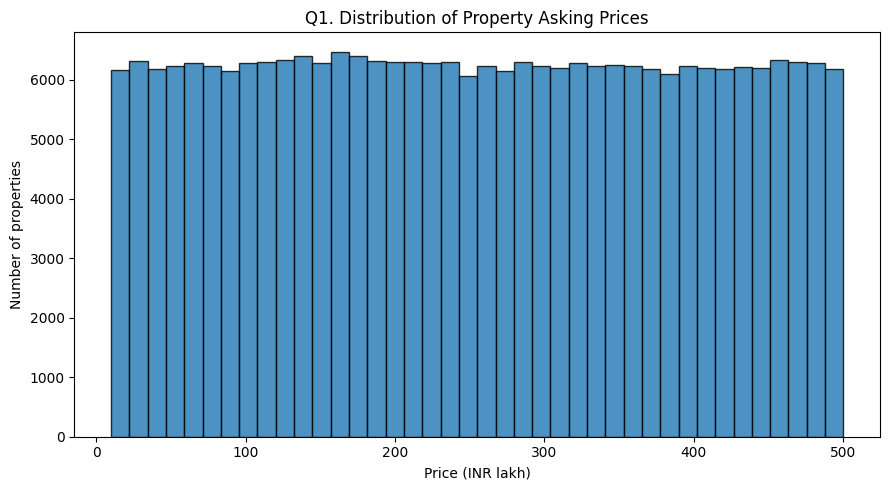

In [8]:
plt.figure(figsize=(9, 5))
plt.hist(housing["Price_in_Lakhs"], bins=40, edgecolor="black", alpha=0.8)
plt.title("Q1. Distribution of Property Asking Prices")
plt.xlabel("Price (INR lakh)")
plt.ylabel("Number of properties")
plt.tight_layout()
plt.show()

### Q2. What is the distribution of property sizes?
A histogram helps identify common property-size ranges and unusually small or large listings.

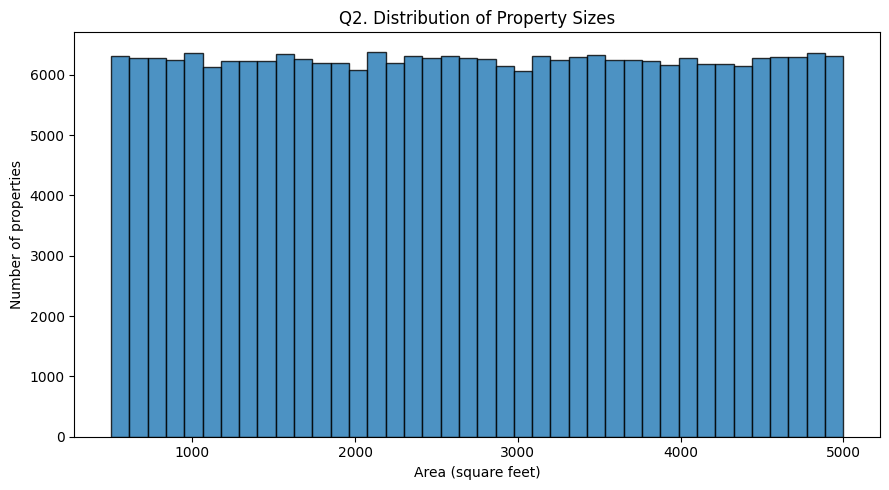

In [9]:
plt.figure(figsize=(9, 5))
plt.hist(housing["Size_in_SqFt"], bins=40, edgecolor="black", alpha=0.8)
plt.title("Q2. Distribution of Property Sizes")
plt.xlabel("Area (square feet)")
plt.ylabel("Number of properties")
plt.tight_layout()
plt.show()

### Q3. How does price per sq ft vary by property type?
The chart uses the calculated INR-per-square-foot measure, not the unvalidated supplied `Price_per_SqFt` column.

,Median calculated price/sqft (INR)
Property_Type,
Independent House,9304.862155
Apartment,9244.506395
Villa,9190.266061


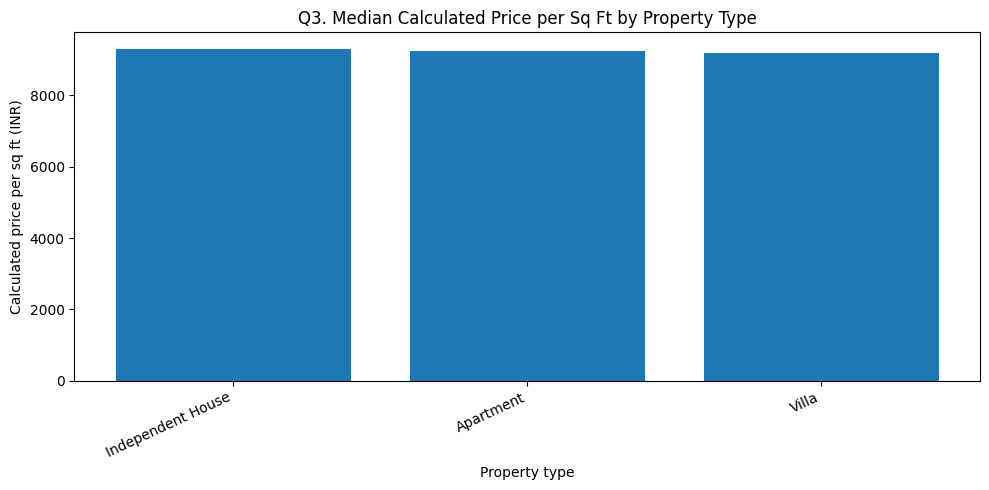

In [10]:
price_sqft_by_type = (
    housing.groupby("Property_Type")["Calculated_Price_per_SqFt_INR"]
    .median().sort_values(ascending=False)
)
display(price_sqft_by_type.rename("Median calculated price/sqft (INR)").to_frame())
plt.figure(figsize=(10, 5))
plt.bar(price_sqft_by_type.index, price_sqft_by_type.values)
plt.title("Q3. Median Calculated Price per Sq Ft by Property Type")
plt.xlabel("Property type")
plt.ylabel("Calculated price per sq ft (INR)")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

### Q4. Is there a relationship between property size and price?
A scatter plot shows association. The visual pattern alone does not prove that size causes a higher price.

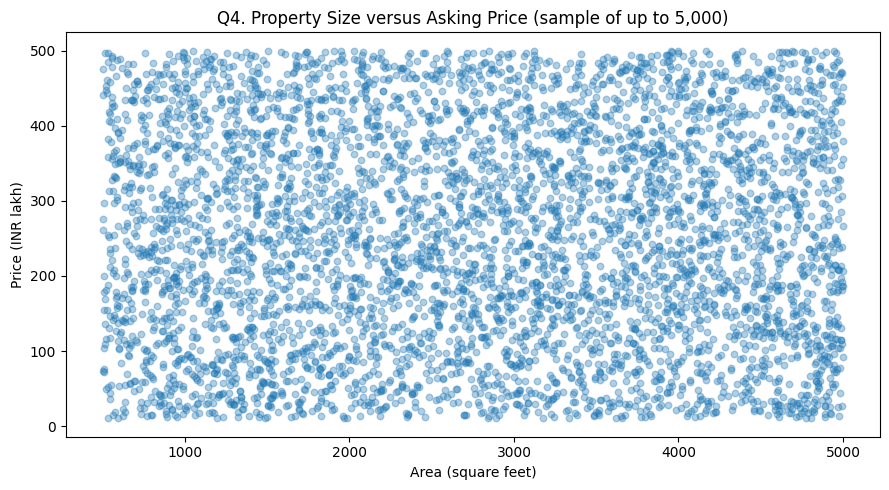

In [11]:
plot_sample = housing.sample(n=min(5000, len(housing)), random_state=42)
plt.figure(figsize=(9, 5))
plt.scatter(plot_sample["Size_in_SqFt"], plot_sample["Price_in_Lakhs"], alpha=0.35, s=22)
plt.title("Q4. Property Size versus Asking Price (sample of up to 5,000)")
plt.xlabel("Area (square feet)")
plt.ylabel("Price (INR lakh)")
plt.tight_layout()
plt.show()

### Q5. Are there outliers in price per sq ft or property size?
A box plot helps flag extreme observations. Outliers are not automatically errors; investigate them before removing anything.

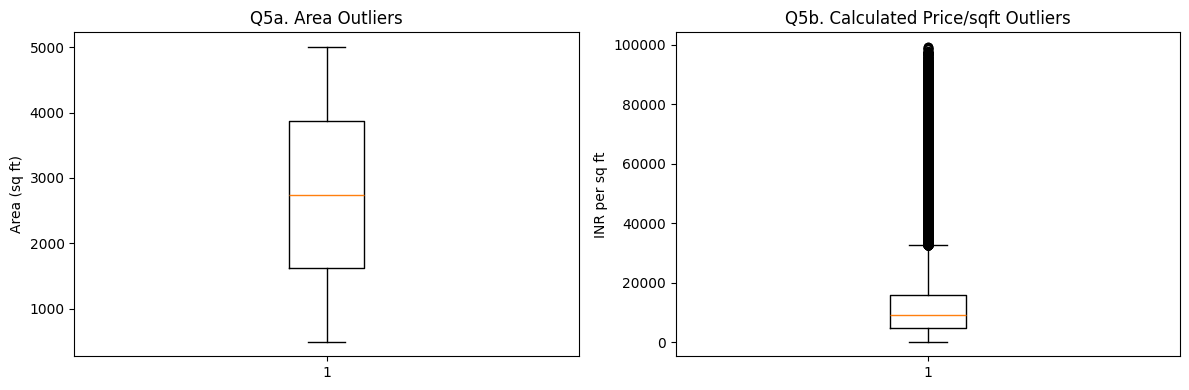

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].boxplot(housing["Size_in_SqFt"], vert=True)
axes[0].set_title("Q5a. Area Outliers")
axes[0].set_ylabel("Area (sq ft)")
axes[1].boxplot(housing["Calculated_Price_per_SqFt_INR"], vert=True)
axes[1].set_title("Q5b. Calculated Price/sqft Outliers")
axes[1].set_ylabel("INR per sq ft")
plt.tight_layout()
plt.show()

## Group B — Location-based analysis (Questions 6–10)

### Q6. What is the average price per sq ft by state?
This compares median calculated price per square foot across states. Median is less affected by extreme listings than the mean.

,Median calculated INR/sqft
State,
Uttar Pradesh,9441.158086
Karnataka,9384.304379
Maharashtra,9360.804513
Gujarat,9330.829559
Tamil Nadu,9301.290054
Telangana,9291.202346
Andhra Pradesh,9286.656707
Assam,9255.012053
Madhya Pradesh,9236.140107


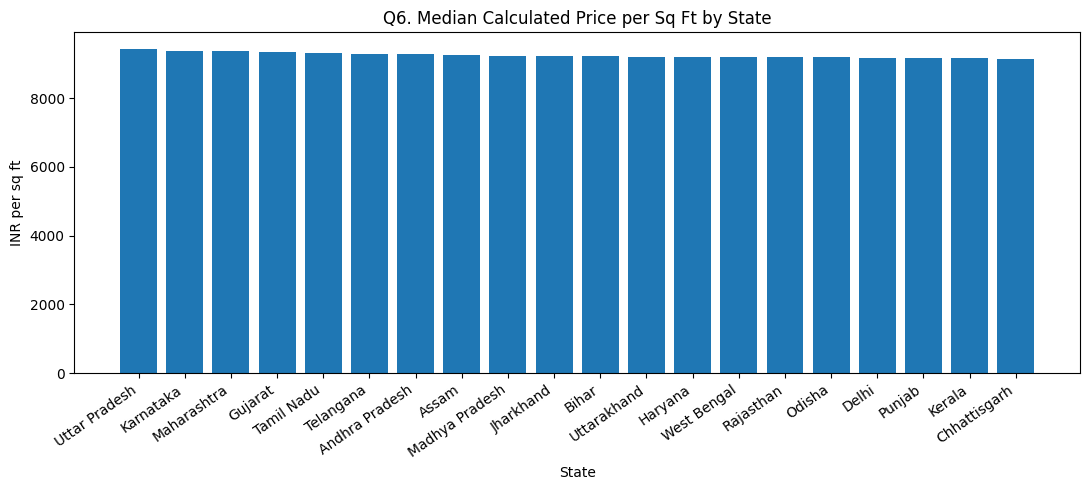

In [13]:
state_price_sqft = (
    housing.groupby("State")["Calculated_Price_per_SqFt_INR"]
    .median().sort_values(ascending=False)
)
display(state_price_sqft.rename("Median calculated INR/sqft").to_frame())
plt.figure(figsize=(11, 5))
plt.bar(state_price_sqft.index, state_price_sqft.values)
plt.title("Q6. Median Calculated Price per Sq Ft by State")
plt.xlabel("State")
plt.ylabel("INR per sq ft")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

### Q7. What is the average property price by city?
The table and chart show the top 12 cities by median asking price.

,Median asking price (INR lakh)
City,
Mysore,259.520
Pune,258.930
Kochi,258.750
Bangalore,258.360
Surat,258.230
Bhopal,258.230
Lucknow,258.040
Gaya,257.200
Dehradun,257.035


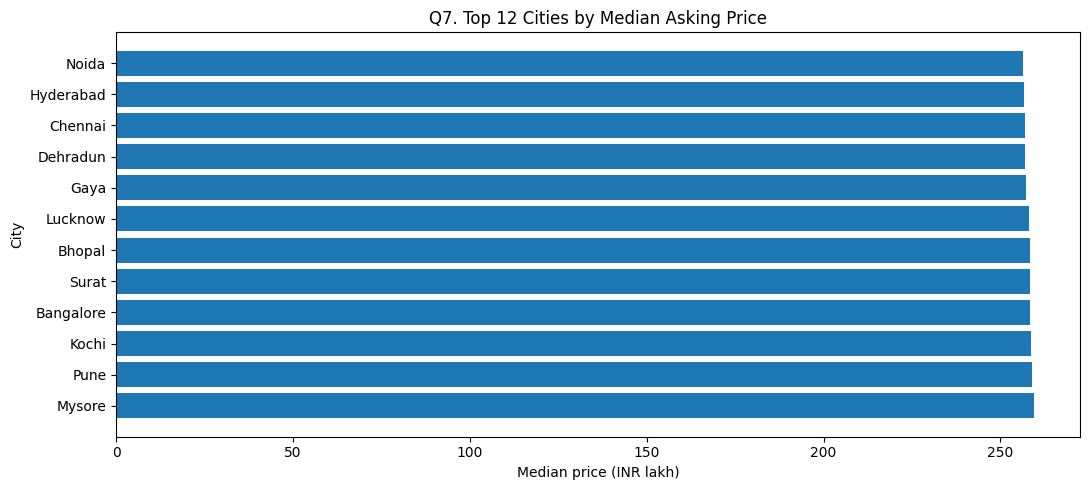

In [14]:
city_price = (
    housing.groupby("City")["Price_in_Lakhs"]
    .median().sort_values(ascending=False).head(12)
)
display(city_price.rename("Median asking price (INR lakh)").to_frame())
plt.figure(figsize=(11, 5))
plt.barh(city_price.index, city_price.values)
plt.title("Q7. Top 12 Cities by Median Asking Price")
plt.xlabel("Median price (INR lakh)")
plt.ylabel("City")
plt.tight_layout()
plt.show()

### Q8. What is the median age of properties by locality?
To keep the display readable, the table shows 15 localities with the most records. This is a sample of localities, not every locality.

,Median property age (years)
Locality,
Locality_224,20.0
Locality_396,20.0
Locality_193,19.0
Locality_297,19.0
Locality_313,19.0
Locality_11,18.0
Locality_105,18.0
Locality_296,18.0
Locality_238,18.0


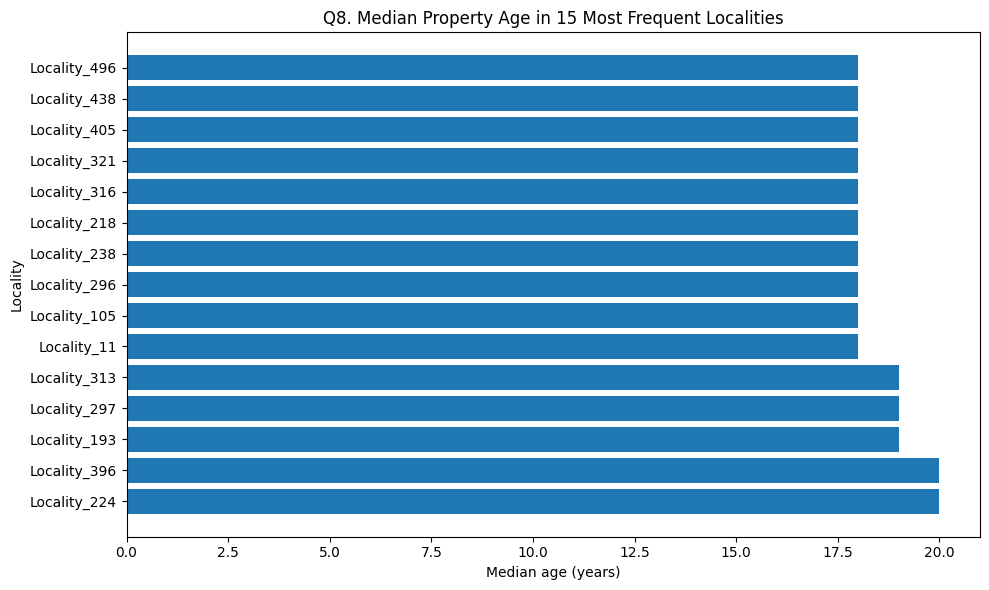

In [15]:
locality_counts = housing["Locality"].value_counts()
selected_localities = locality_counts.head(15).index
locality_age = (
    housing[housing["Locality"].isin(selected_localities)]
    .groupby("Locality")["Age_of_Property"].median()
    .sort_values(ascending=False)
)
display(locality_age.rename("Median property age (years)").to_frame())
plt.figure(figsize=(10, 6))
plt.barh(locality_age.index, locality_age.values)
plt.title("Q8. Median Property Age in 15 Most Frequent Localities")
plt.xlabel("Median age (years)")
plt.ylabel("Locality")
plt.tight_layout()
plt.show()

### Q9. How is BHK distributed across cities?
The table uses the eight cities with the largest number of records and shows their BHK mix.

BHK,1,2,3,4,5
City,,,,,
Ahmedabad,0.197,0.198,0.198,0.196,0.211
Bhubaneswar,0.195,0.204,0.205,0.192,0.202
Coimbatore,0.191,0.201,0.204,0.208,0.195
Cuttack,0.208,0.203,0.205,0.194,0.190
Durgapur,0.205,0.197,0.202,0.197,0.199
Jamshedpur,0.201,0.193,0.209,0.201,0.196
Silchar,0.194,0.196,0.207,0.195,0.209
Vijayawada,0.190,0.203,0.204,0.210,0.193


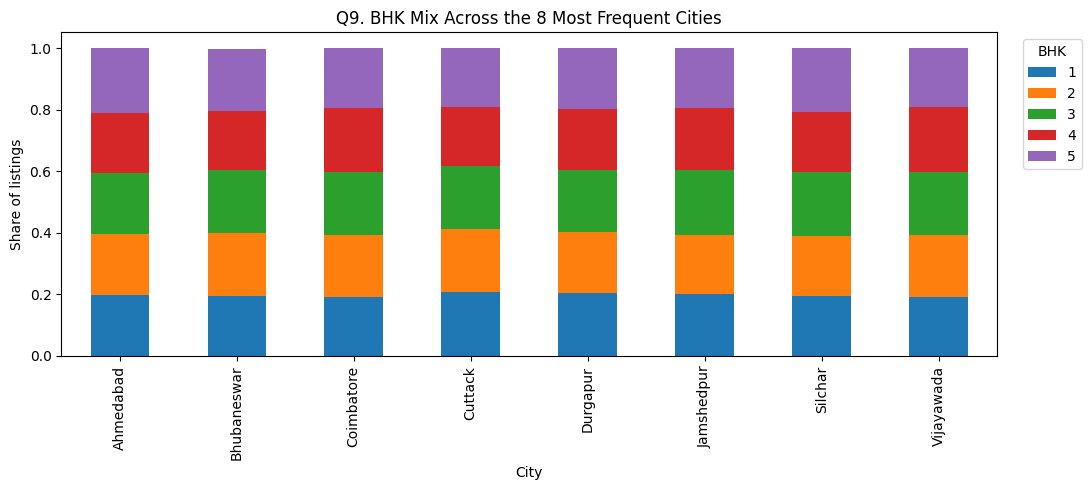

In [16]:
top_cities = housing["City"].value_counts().head(8).index
bhk_city = pd.crosstab(
    housing.loc[housing["City"].isin(top_cities), "City"],
    housing.loc[housing["City"].isin(top_cities), "BHK"],
    normalize="index"
).round(3)
display(bhk_city)
bhk_city.plot(kind="bar", stacked=True, figsize=(11, 5))
plt.title("Q9. BHK Mix Across the 8 Most Frequent Cities")
plt.xlabel("City")
plt.ylabel("Share of listings")
plt.legend(title="BHK", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

### Q10. What are the price trends for the top 5 most expensive localities?
The source table does not contain a time-series date column, so a time trend cannot be calculated. This section instead shows the five localities with the highest median asking price.

,Median asking price (INR lakh)
Locality,
Locality_395,282.680
Locality_366,282.330
Locality_303,282.270
Locality_79,280.760
Locality_203,280.325


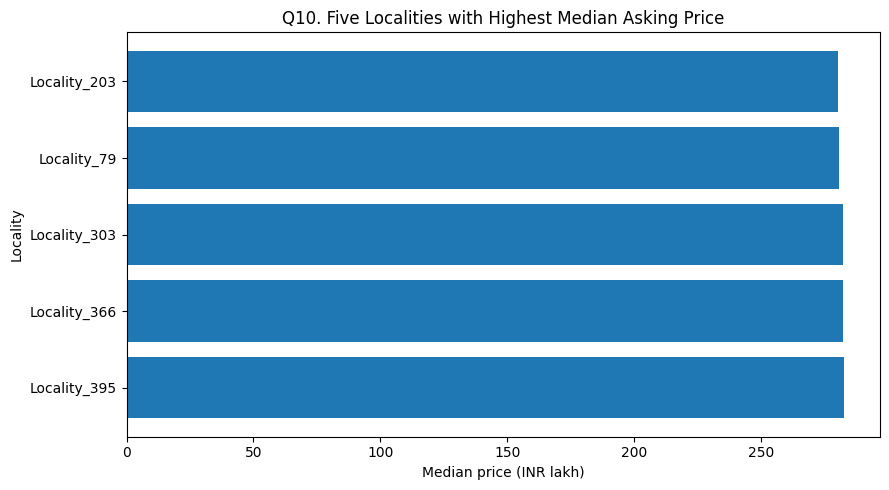

In [17]:
top_localities = (
    housing.groupby("Locality")["Price_in_Lakhs"]
    .median().sort_values(ascending=False).head(5)
)
display(top_localities.rename("Median asking price (INR lakh)").to_frame())
plt.figure(figsize=(9, 5))
plt.barh(top_localities.index, top_localities.values)
plt.title("Q10. Five Localities with Highest Median Asking Price")
plt.xlabel("Median price (INR lakh)")
plt.ylabel("Locality")
plt.tight_layout()
plt.show()

## Group C — Feature relationship and correlation (Questions 11–15)

### Q11. How are numeric features correlated with each other?
Correlation values range from −1 to +1. Positive values move together, negative values move in opposite directions, and values near zero indicate weak linear association.

,BHK,Size_in_SqFt,Price_in_Lakhs,Calculated_Price_per_SqFt_INR,Year_Built,Age_of_Property,Nearby_Schools,Nearby_Hospitals,Floor_No,Total_Floors
BHK,1.0,-0.00,-0.00,0.00,0.0,-0.0,-0.0,0.00,0.0,-0.00
Size_in_SqFt,-0.0,1.00,-0.00,-0.61,0.0,-0.0,0.0,-0.00,-0.0,-0.00
Price_in_Lakhs,-0.0,-0.00,1.00,0.56,0.0,-0.0,0.0,-0.00,-0.0,0.00
Calculated_Price_per_SqFt_INR,0.0,-0.61,0.56,1.00,-0.0,0.0,-0.0,-0.00,-0.0,0.00
Year_Built,0.0,0.00,0.00,-0.00,1.0,-1.0,-0.0,-0.00,-0.0,0.00
Age_of_Property,-0.0,-0.00,-0.00,0.00,-1.0,1.0,0.0,0.00,0.0,-0.00
Nearby_Schools,-0.0,0.00,0.00,-0.00,-0.0,0.0,1.0,-0.00,-0.0,-0.00
Nearby_Hospitals,0.0,-0.00,-0.00,-0.00,-0.0,0.0,-0.0,1.00,0.0,-0.01
Floor_No,0.0,-0.00,-0.00,-0.00,-0.0,0.0,-0.0,0.00,1.0,0.00
Total_Floors,-0.0,-0.00,0.00,0.00,0.0,-0.0,-0.0,-0.01,0.0,1.00


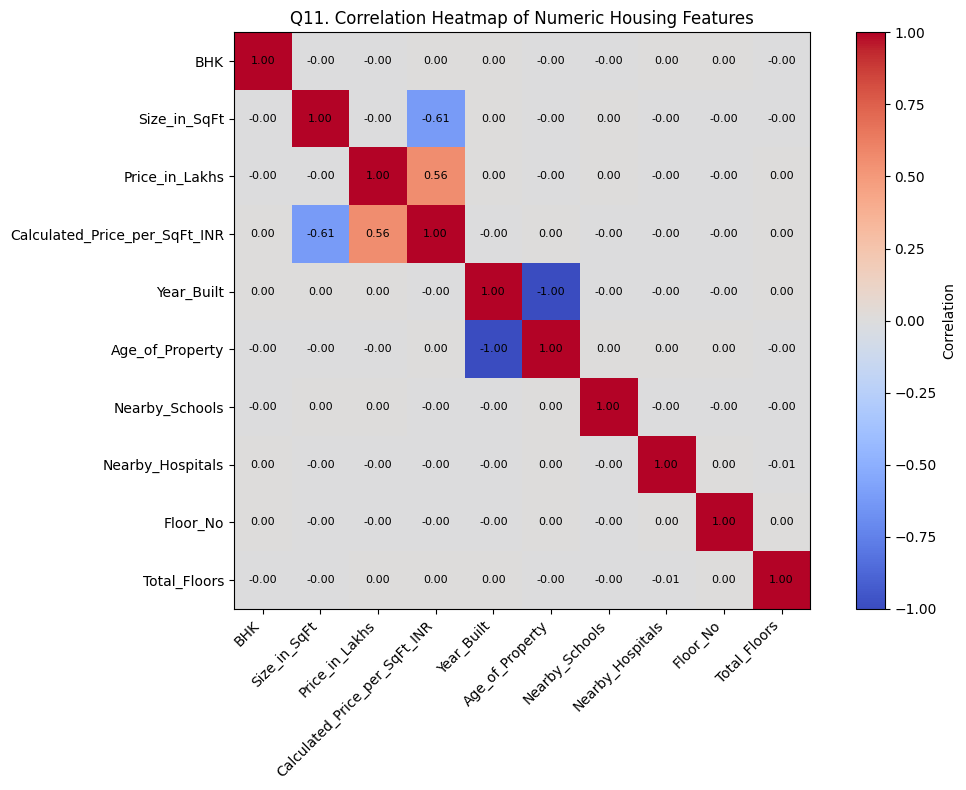

In [18]:
numeric_columns = [
    "BHK", "Size_in_SqFt", "Price_in_Lakhs", "Calculated_Price_per_SqFt_INR",
    "Year_Built", "Age_of_Property", "Nearby_Schools", "Nearby_Hospitals",
    "Floor_No", "Total_Floors"
]
correlation_matrix = housing[numeric_columns].corr()
display(correlation_matrix.round(2))
plt.figure(figsize=(11, 8))
im = plt.imshow(correlation_matrix, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(im, label="Correlation")
plt.xticks(range(len(correlation_matrix.columns)), correlation_matrix.columns, rotation=45, ha="right")
plt.yticks(range(len(correlation_matrix.index)), correlation_matrix.index)
for row in range(len(correlation_matrix.index)):
    for col in range(len(correlation_matrix.columns)):
        plt.text(col, row, f"{correlation_matrix.iloc[row, col]:.2f}", ha="center", va="center", fontsize=8)
plt.title("Q11. Correlation Heatmap of Numeric Housing Features")
plt.tight_layout()
plt.show()

### Q12. How do nearby schools relate to price per sq ft?
The box plot compares calculated price-per-square-foot across the school-count values.

,Median calculated INR/sqft
Nearby_Schools,
1,9260.546628
2,9291.488059
3,9273.342355
4,9258.669355
5,9187.979967
6,9351.664999
7,9232.543759
8,9144.034993
9,9264.525994


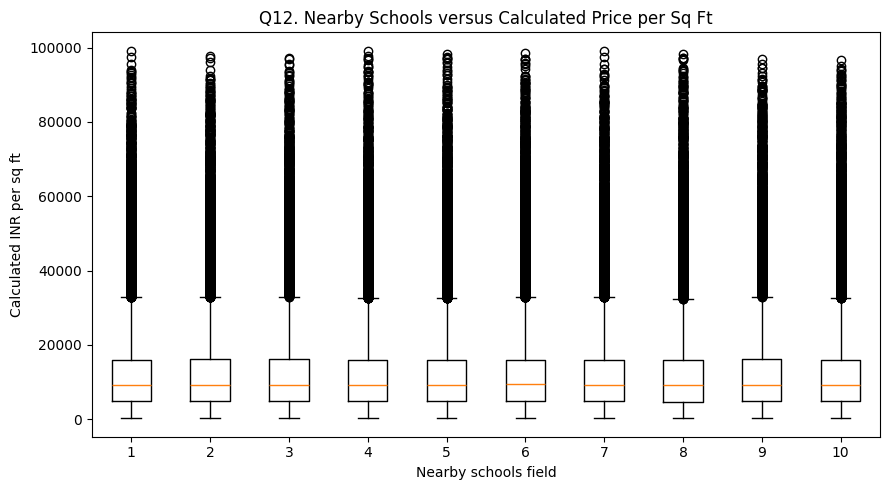

In [19]:
school_price = housing.groupby("Nearby_Schools")["Calculated_Price_per_SqFt_INR"].median()
display(school_price.rename("Median calculated INR/sqft").to_frame())
plt.figure(figsize=(9, 5))
school_levels = sorted(housing["Nearby_Schools"].unique())
school_values = [housing.loc[housing["Nearby_Schools"] == level, "Calculated_Price_per_SqFt_INR"] for level in school_levels]
plt.boxplot(school_values)
plt.xticks(range(1, len(school_levels) + 1), school_levels)
plt.title("Q12. Nearby Schools versus Calculated Price per Sq Ft")
plt.xlabel("Nearby schools field")
plt.ylabel("Calculated INR per sq ft")
plt.tight_layout()
plt.show()

### Q13. How do nearby hospitals relate to price per sq ft?
This analysis is descriptive. Other factors such as city and locality may also explain price differences.

,Median calculated INR/sqft
Nearby_Hospitals,
1,9256.410256
2,9309.116526
3,9348.720669
4,9270.739224
5,9148.837033
6,9128.695602
7,9334.331337
8,9223.891811
9,9283.421469


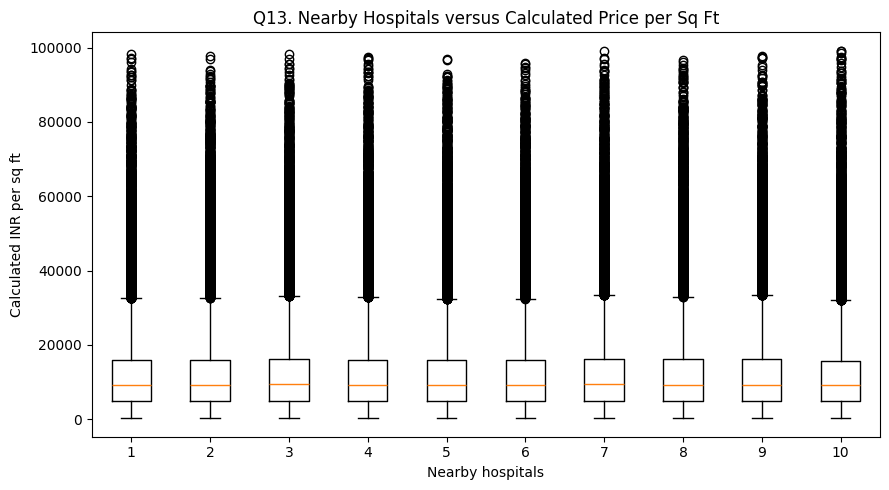

In [20]:
hospital_price = housing.groupby("Nearby_Hospitals")["Calculated_Price_per_SqFt_INR"].median()
display(hospital_price.rename("Median calculated INR/sqft").to_frame())
plt.figure(figsize=(9, 5))
hospital_levels = sorted(housing["Nearby_Hospitals"].unique())
hospital_values = [housing.loc[housing["Nearby_Hospitals"] == level, "Calculated_Price_per_SqFt_INR"] for level in hospital_levels]
plt.boxplot(hospital_values)
plt.xticks(range(1, len(hospital_levels) + 1), hospital_levels)
plt.title("Q13. Nearby Hospitals versus Calculated Price per Sq Ft")
plt.xlabel("Nearby hospitals")
plt.ylabel("Calculated INR per sq ft")
plt.tight_layout()
plt.show()

### Q14. How does price vary by furnished status?
The chart compares median asking price for each furnishing category.

,Median price (INR lakh)
Furnished_Status,
Unfurnished,254.190
Semi-furnished,253.810
Furnished,253.555


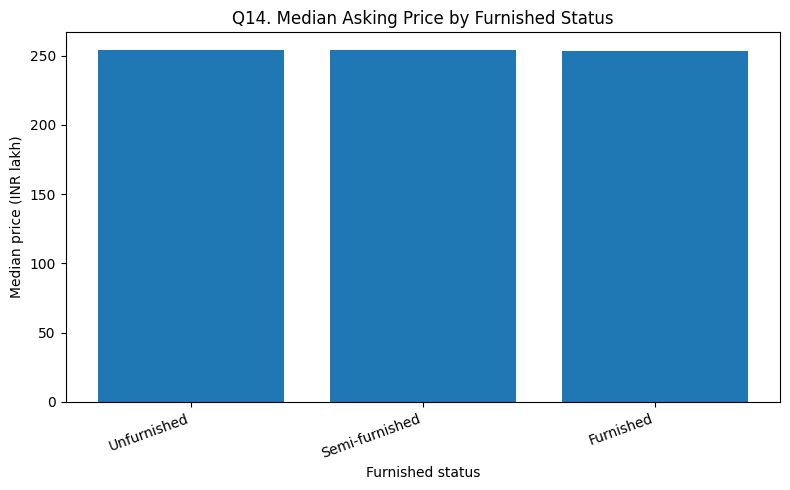

In [21]:
furnishing_price = housing.groupby("Furnished_Status")["Price_in_Lakhs"].median().sort_values(ascending=False)
display(furnishing_price.rename("Median price (INR lakh)").to_frame())
plt.figure(figsize=(8, 5))
plt.bar(furnishing_price.index, furnishing_price.values)
plt.title("Q14. Median Asking Price by Furnished Status")
plt.xlabel("Furnished status")
plt.ylabel("Median price (INR lakh)")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

### Q15. How does price per sq ft vary by property facing direction?
Compare the median calculated INR-per-square-foot for each facing category.

,Median calculated INR/sqft
Facing,
West,9307.593966
East,9234.005563
South,9224.633252
North,9219.230769


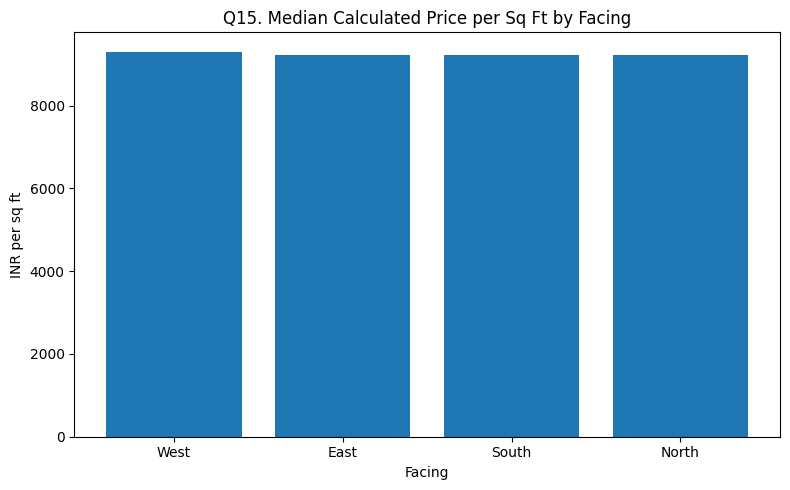

In [22]:
facing_price = housing.groupby("Facing")["Calculated_Price_per_SqFt_INR"].median().sort_values(ascending=False)
display(facing_price.rename("Median calculated INR/sqft").to_frame())
plt.figure(figsize=(8, 5))
plt.bar(facing_price.index, facing_price.values)
plt.title("Q15. Median Calculated Price per Sq Ft by Facing")
plt.xlabel("Facing")
plt.ylabel("INR per sq ft")
plt.tight_layout()
plt.show()

## Group D — Investment, amenities and ownership analysis (Questions 16–20)

### Q16. How many properties belong to each owner type?
A count chart shows the number of listings in each owner category.

,Property count
Owner_Type,
Broker,83479
Owner,83268
Builder,83253


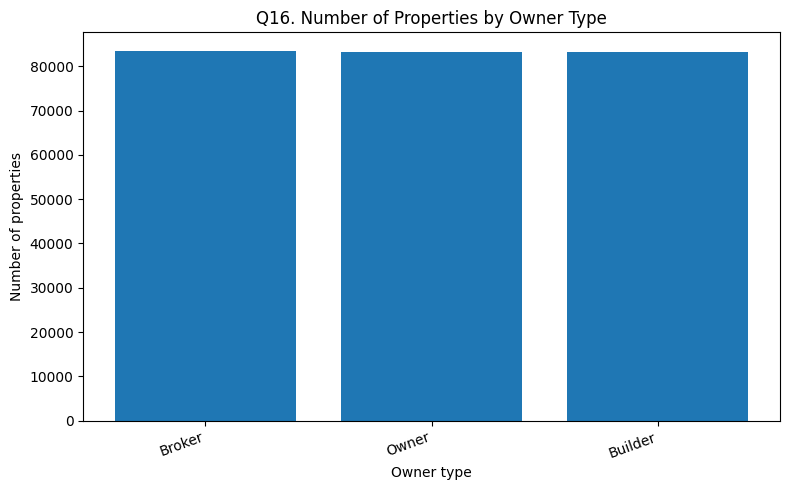

In [23]:
owner_counts = housing["Owner_Type"].value_counts()
display(owner_counts.rename("Property count").to_frame())
plt.figure(figsize=(8, 5))
plt.bar(owner_counts.index, owner_counts.values)
plt.title("Q16. Number of Properties by Owner Type")
plt.xlabel("Owner type")
plt.ylabel("Number of properties")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

### Q17. How many properties are available under each availability status?
This helps describe the composition of the listing dataset by availability status.

,Property count
Availability_Status,
Under_Construction,125035
Ready_to_Move,124965


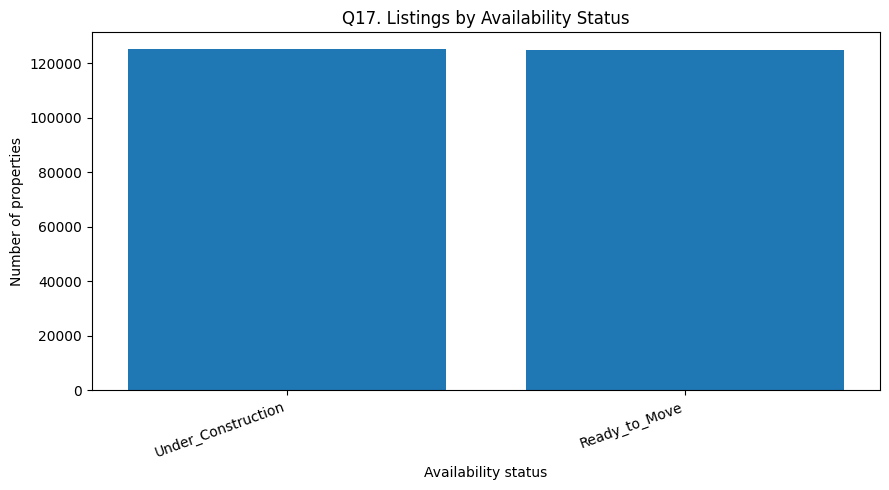

In [24]:
availability_counts = housing["Availability_Status"].value_counts()
display(availability_counts.rename("Property count").to_frame())
plt.figure(figsize=(9, 5))
plt.bar(availability_counts.index, availability_counts.values)
plt.title("Q17. Listings by Availability Status")
plt.xlabel("Availability status")
plt.ylabel("Number of properties")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

### Q18. Does parking space affect property price?
The chart compares asking-price distributions by parking category. This is an association, not proof that parking alone determines price.

,count,median,mean
Parking_Space,,,
No,125456,253.37,254.43
Yes,124544,254.36,254.75


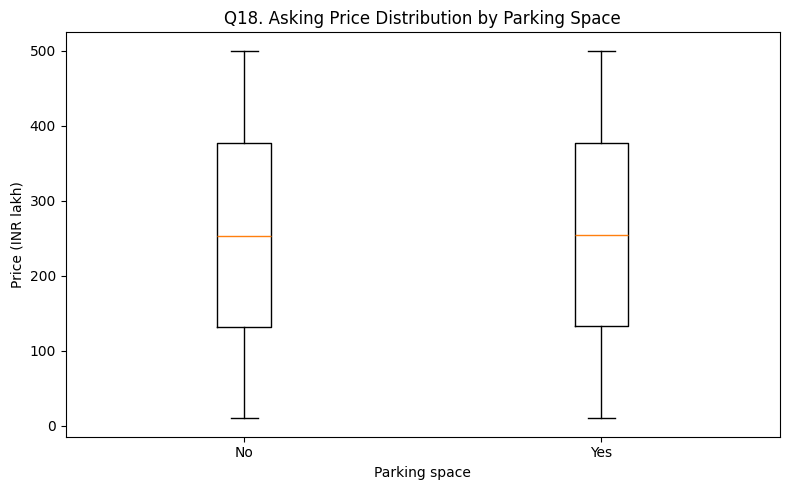

In [25]:
parking_summary = housing.groupby("Parking_Space")["Price_in_Lakhs"].agg(["count", "median", "mean"]).round(2)
display(parking_summary)
plt.figure(figsize=(8, 5))
parking_levels = sorted(housing["Parking_Space"].dropna().unique())
parking_values = [housing.loc[housing["Parking_Space"] == level, "Price_in_Lakhs"] for level in parking_levels]
plt.boxplot(parking_values)
plt.xticks(range(1, len(parking_levels) + 1), parking_levels)
plt.title("Q18. Asking Price Distribution by Parking Space")
plt.xlabel("Parking space")
plt.ylabel("Price (INR lakh)")
plt.tight_layout()
plt.show()

### Q19. How do amenities affect price per sq ft?
The `Amenities` field contains comma-separated amenity names. The code expands these values and compares median calculated price per square foot for frequently occurring amenities.

,count,median
Amenity,,
Garden,150177,9247.11
Pool,150096,9249.32
Clubhouse,150059,9242.13
Gym,149960,9268.70
Playground,149780,9260.12


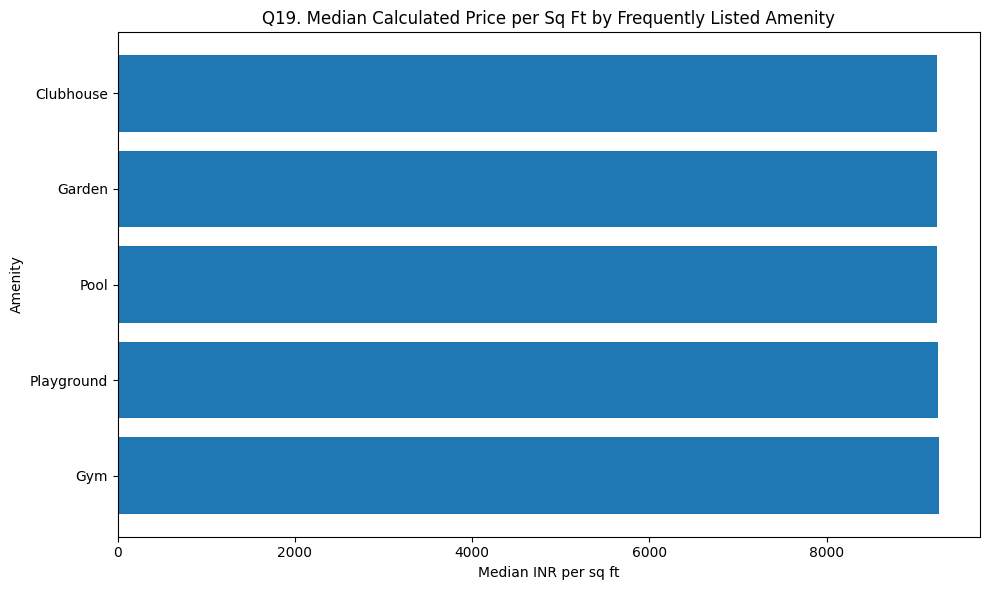

In [26]:
amenity_rows = housing[["Amenities", "Calculated_Price_per_SqFt_INR"]].copy()
amenity_rows["Amenities"] = amenity_rows["Amenities"].fillna("")
amenity_rows["Amenity"] = amenity_rows["Amenities"].str.split(",")
amenity_rows = amenity_rows.explode("Amenity")
amenity_rows["Amenity"] = amenity_rows["Amenity"].str.strip()
amenity_rows = amenity_rows[amenity_rows["Amenity"].ne("")]
amenity_summary = (
    amenity_rows.groupby("Amenity")["Calculated_Price_per_SqFt_INR"]
    .agg(["count", "median"]).sort_values("count", ascending=False).head(12)
)
display(amenity_summary.round(2))
amenity_plot = amenity_summary.sort_values("median", ascending=False)
plt.figure(figsize=(10, 6))
plt.barh(amenity_plot.index, amenity_plot["median"])
plt.title("Q19. Median Calculated Price per Sq Ft by Frequently Listed Amenity")
plt.xlabel("Median INR per sq ft")
plt.ylabel("Amenity")
plt.tight_layout()
plt.show()

### Q20. How does public transport accessibility relate to price per sq ft or investment potential?
The chart compares median calculated INR per square foot across the accessibility categories in the housing dataset.

,count,median,mean
Public_Transport_Accessibility,,,
Medium,83008,9269.31,13062.23
Low,83287,9265.33,13085.54
High,83705,9205.08,13027.24


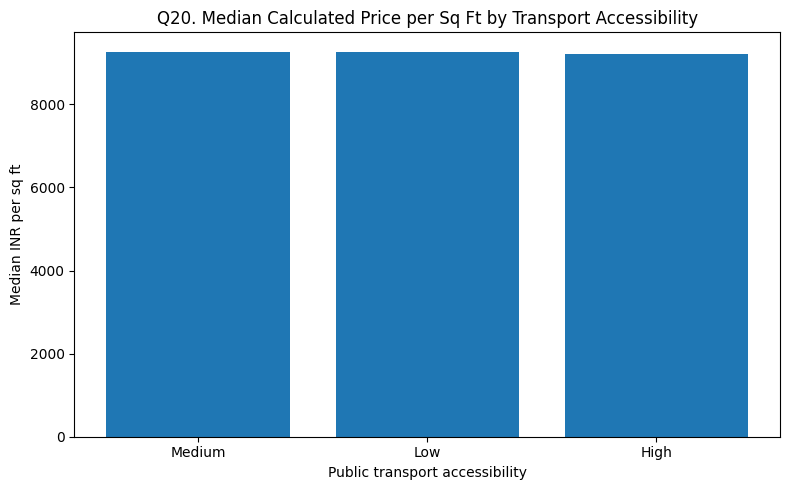

In [27]:
transport_summary = (
    housing.groupby("Public_Transport_Accessibility")["Calculated_Price_per_SqFt_INR"]
    .agg(["count", "median", "mean"]).sort_values("median", ascending=False)
)
display(transport_summary.round(2))
plt.figure(figsize=(8, 5))
plt.bar(transport_summary.index, transport_summary["median"])
plt.title("Q20. Median Calculated Price per Sq Ft by Transport Accessibility")
plt.xlabel("Public transport accessibility")
plt.ylabel("Median INR per sq ft")
plt.tight_layout()
plt.show()

# 9. Synthetic investment dataset exploration

The following charts use the separate synthetic investment dataset that supports the Phase 4 and Phase 5 modelling workflow. These plots should be interpreted as patterns in generated data, not real estate market evidence.

In [28]:
investment_numeric_summary = investment[[
    "Price_INR_Lakhs", "Area_SqFt", "Net_Rental_Yield_Pct",
    "Assumed_Annual_Appreciation_Rate_Pct",
    "Distance_to_CBD_km", "Amenities_Score_1_to_10",
    "Projected_Value_After_5Y_INR_Lakhs",
]].describe().T
display(investment_numeric_summary.round(2))

,count,mean,std,min,25%,50%,75%,max
Price_INR_Lakhs,5000.0,118.79,72.52,15.37,69.12,100.43,146.61,670.70
Area_SqFt,5000.0,1456.66,393.84,328.00,1177.75,1429.50,1721.00,2664.00
Net_Rental_Yield_Pct,5000.0,3.21,0.80,0.88,2.66,3.20,3.75,6.07
Assumed_Annual_Appreciation_Rate_Pct,5000.0,7.84,2.06,2.50,6.45,7.81,9.23,14.98
Distance_to_CBD_km,5000.0,7.09,4.86,0.50,3.50,6.00,9.50,30.00
Amenities_Score_1_to_10,5000.0,5.47,2.87,1.00,3.00,5.00,8.00,10.00
Projected_Value_After_5Y_INR_Lakhs,5000.0,173.44,106.13,20.77,100.66,146.25,214.00,1014.58


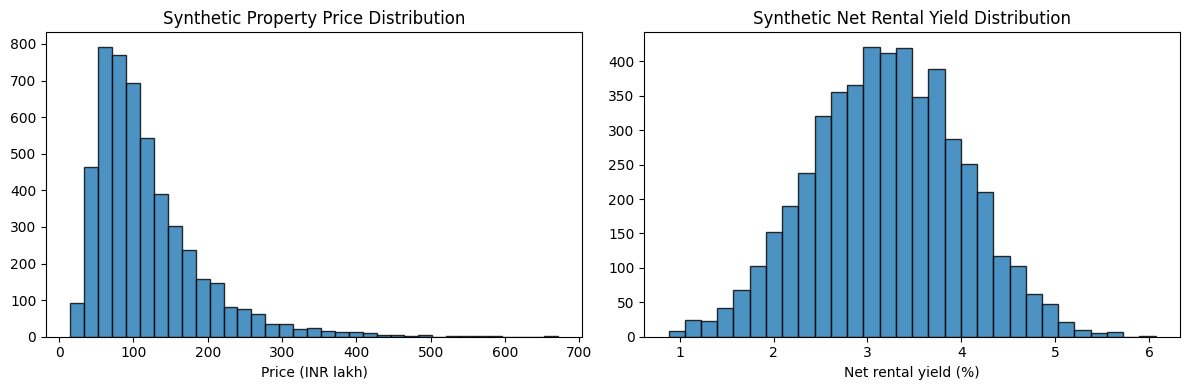

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(investment["Price_INR_Lakhs"], bins=35, edgecolor="black", alpha=0.8)
axes[0].set_title("Synthetic Property Price Distribution")
axes[0].set_xlabel("Price (INR lakh)")
axes[1].hist(investment["Net_Rental_Yield_Pct"], bins=30, edgecolor="black", alpha=0.8)
axes[1].set_title("Synthetic Net Rental Yield Distribution")
axes[1].set_xlabel("Net rental yield (%)")
plt.tight_layout()
plt.show()

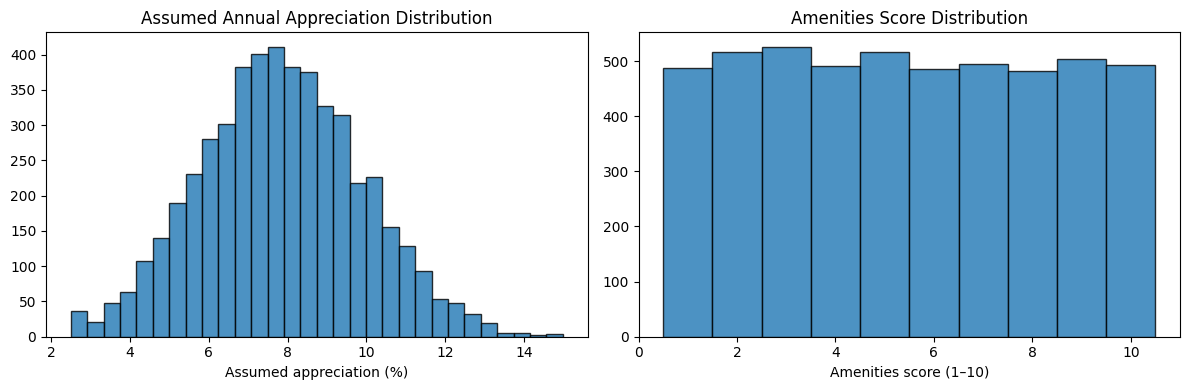

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(investment["Assumed_Annual_Appreciation_Rate_Pct"], bins=30, edgecolor="black", alpha=0.8)
axes[0].set_title("Assumed Annual Appreciation Distribution")
axes[0].set_xlabel("Assumed appreciation (%)")
axes[1].hist(investment["Amenities_Score_1_to_10"], bins=np.arange(0.5, 11.5, 1), edgecolor="black", alpha=0.8)
axes[1].set_title("Amenities Score Distribution")
axes[1].set_xlabel("Amenities score (1–10)")
plt.tight_layout()
plt.show()

,Property count
Good_Investment_Label,
Not Good (0),3834
Good (1),1166


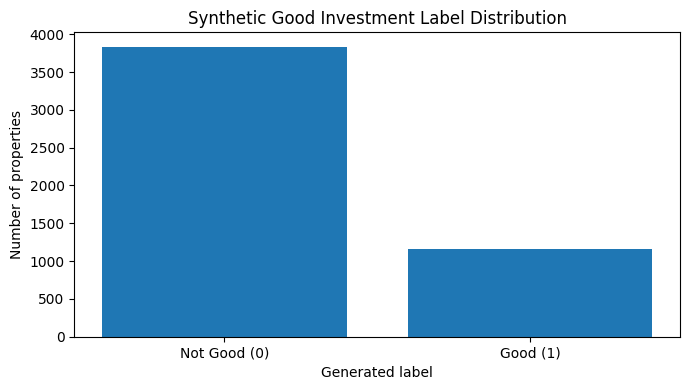

In [31]:
label_counts = investment["Good_Investment_Label"].value_counts().sort_index()
label_names = label_counts.rename(index={0: "Not Good (0)", 1: "Good (1)"})
display(label_names.rename("Property count").to_frame())
plt.figure(figsize=(7, 4))
plt.bar(label_names.index, label_names.values)
plt.title("Synthetic Good Investment Label Distribution")
plt.xlabel("Generated label")
plt.ylabel("Number of properties")
plt.tight_layout()
plt.show()

In [32]:
label_profiles = investment.groupby("Good_Investment_Label")[[
    "Net_Rental_Yield_Pct",
    "Assumed_Annual_Appreciation_Rate_Pct",
    "Distance_to_CBD_km",
    "Amenities_Score_1_to_10",
]].mean().round(2)
display(label_profiles)

,Net_Rental_Yield_Pct,Assumed_Annual_Appreciation_Rate_Pct,Distance_to_CBD_km,Amenities_Score_1_to_10
Good_Investment_Label,,,,
0,3.04,7.36,7.38,4.99
1,3.75,9.40,6.15,7.05


# 10. Model development and algorithms

The project contains two classification models and two regression models, plus baselines.

## 10.1 Classification algorithms

**Logistic Regression**  
A classification algorithm that estimates the probability of a class. The result can be converted to a 0/1 class using a threshold.

**Decision Tree Classifier**  
Splits records using feature-based decision rules. It can model non-linear decision boundaries but may overfit if not controlled.

## 10.2 Regression algorithms

**Linear Regression**  
Fits a linear relationship between predictor variables and a continuous target.

**Random Forest Regressor**  
Combines predictions from many decision trees. It can represent non-linear patterns but is less directly interpretable than a simple linear model.

## 10.3 Baselines

A majority-class baseline predicts the most common classification class. A mean-value baseline predicts the mean regression target. These provide reference points for deciding whether the trained models improve on simple strategies.

In [33]:
model_summary = pd.DataFrame([
    ("Classification", "Logistic Regression", "Good Investment label", "ROC-AUC"),
    ("Classification", "Decision Tree Classifier", "Good Investment label", "ROC-AUC"),
    ("Classification", "Majority Baseline", "Good Investment label", "Accuracy / reference"),
    ("Regression", "Linear Regression", "Five-year projected value", "MAE, RMSE, R²"),
    ("Regression", "Random Forest Regressor", "Five-year projected value", "MAE, RMSE, R²"),
    ("Regression", "Mean Baseline", "Five-year projected value", "MAE, RMSE, R²"),
], columns=["Task", "Model", "Target", "Evaluation"])
display(model_summary)

,Task,Model,Target,Evaluation
0,Classification,Logistic Regression,Good Investment label,ROC-AUC
1,Classification,Decision Tree Classifier,Good Investment label,ROC-AUC
2,Classification,Majority Baseline,Good Investment label,Accuracy / reference
3,Regression,Linear Regression,Five-year projected value,"MAE, RMSE, R²"
4,Regression,Random Forest Regressor,Five-year projected value,"MAE, RMSE, R²"
5,Regression,Mean Baseline,Five-year projected value,"MAE, RMSE, R²"


# 11. Model evaluation and recorded results

The following numbers are the recorded Phase 5 results from the project report. They are not recalculated in this notebook. They came from the synthetic dataset and a fixed train/test split.

In [34]:
classification_results = pd.DataFrame([
    ("Logistic Regression", 0.8050, 0.6258, 0.4145, 0.4987, 0.8226),
    ("Decision Tree Classifier", 0.7960, 0.5789, 0.4701, 0.5189, 0.8362),
    ("Majority Baseline", 0.7660, 0.0000, 0.0000, 0.0000, np.nan),
], columns=["Model", "Accuracy", "Precision", "Recall", "F1", "ROC-AUC"])
display(classification_results)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,0.805,0.6258,0.4145,0.4987,0.8226
1,Decision Tree Classifier,0.796,0.5789,0.4701,0.5189,0.8362
2,Majority Baseline,0.766,0.0000,0.0000,0.0000,NaN


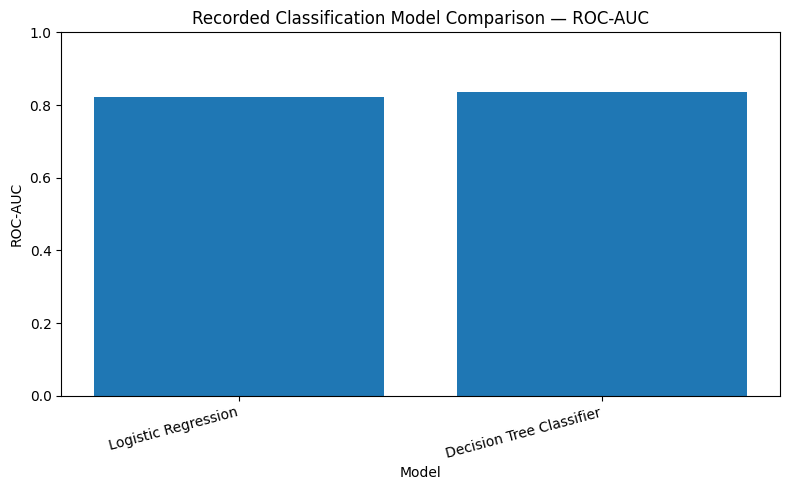

In [35]:
plt.figure(figsize=(8, 5))
chart_data = classification_results.dropna(subset=["ROC-AUC"])
plt.bar(chart_data["Model"], chart_data["ROC-AUC"])
plt.ylim(0, 1)
plt.title("Recorded Classification Model Comparison — ROC-AUC")
plt.xlabel("Model")
plt.ylabel("ROC-AUC")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()

In [36]:
regression_results = pd.DataFrame([
    ("Linear Regression", 11.5834, 17.2580, 0.9689),
    ("Random Forest Regressor", 11.9680, 17.8242, 0.9669),
    ("Mean Baseline", 73.3024, 98.1463, -0.0045),
], columns=["Model", "MAE_INR_Lakhs", "RMSE_INR_Lakhs", "R_squared"])
display(regression_results)

,Model,MAE_INR_Lakhs,RMSE_INR_Lakhs,R_squared
0,Linear Regression,11.5834,17.2580,0.9689
1,Random Forest Regressor,11.9680,17.8242,0.9669
2,Mean Baseline,73.3024,98.1463,-0.0045


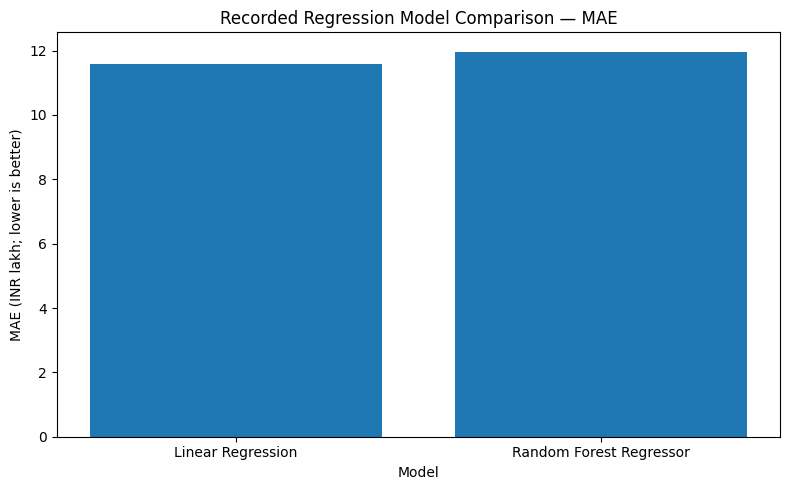

In [37]:
trained_regression = regression_results[regression_results["Model"] != "Mean Baseline"]
plt.figure(figsize=(8, 5))
plt.bar(trained_regression["Model"], trained_regression["MAE_INR_Lakhs"])
plt.title("Recorded Regression Model Comparison — MAE")
plt.xlabel("Model")
plt.ylabel("MAE (INR lakh; lower is better)")
plt.tight_layout()
plt.show()

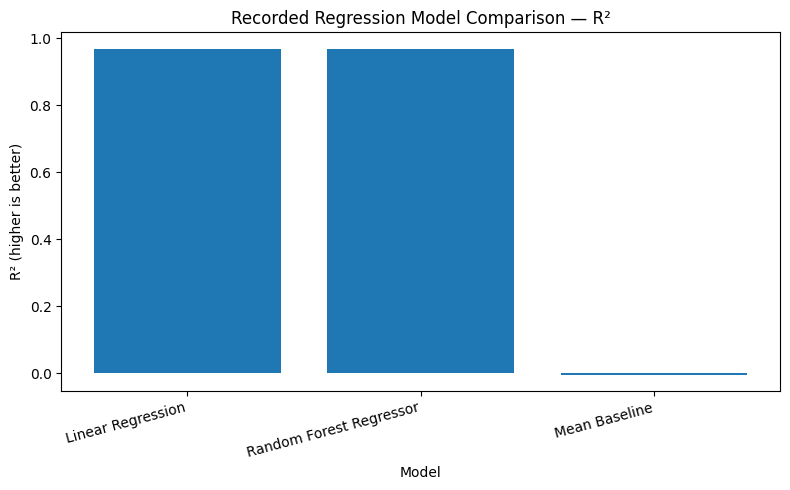

In [38]:
plt.figure(figsize=(8, 5))
plt.bar(regression_results["Model"], regression_results["R_squared"])
plt.title("Recorded Regression Model Comparison — R²")
plt.xlabel("Model")
plt.ylabel("R² (higher is better)")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()

## 11.1 How to interpret the metrics

### Classification
- **Accuracy:** fraction of all predictions that are correct.
- **Precision:** among records predicted as Good Investment, how many have label 1?
- **Recall:** among all records with label 1, how many did the model identify?
- **F1-score:** balances precision and recall.
- **ROC-AUC:** measures how well the model ranks positive cases above negative cases across thresholds. A score closer to 1 indicates stronger ranking performance on that evaluation set.

The positive class represents 23.42% of prepared records, so accuracy alone is insufficient.

### Regression
- **MAE:** average absolute prediction error, in this project's case INR lakh.
- **RMSE:** square root of average squared error; it penalises larger errors more strongly.
- **R²:** relative fit compared with predicting the test-set mean.

The recorded Linear Regression model has lower MAE and higher R² than the Random Forest Regressor in this specific run. This does not establish that Linear Regression will generalise better to real properties.

# 12. MLflow experiment tracking

MLflow is used in Phase 6 to track model runs, parameters, metrics and artifacts.

### What was recorded
The project report records six completed runs:
- Logistic Regression
- Decision Tree Classifier
- Majority Baseline
- Linear Regression
- Random Forest Regressor
- Mean Baseline

### Launch the local MLflow interface

Run these commands in a separate PowerShell terminal from the project root:
```powershell
.\.venv\Scripts\Activate.ps1
$env:MLFLOW_ALLOW_FILE_STORE = "true"
mlflow ui --backend-store-uri ./mlruns --port 5000
```

Open `http://127.0.0.1:5000`. The local MLflow UI is different from the public Streamlit app.

# 13. Streamlit application and public deployment

The Streamlit application is implemented in `app.py`. It loads the saved Phase 5 pipelines and metadata, accepts user-entered property attributes, validates inputs, and displays model outputs.

### Main application flow

1. The user selects city, locality tier, property type and property characteristics.
2. The application builds a feature row in the exact saved model feature order.
3. The classification pipeline returns the predicted label and probability (when supported).
4. The regression pipeline estimates the projected five-year property value.
5. The app displays a scenario summary and a visual comparison.

### Public application

**[OPEN THE LIVE STREAMLIT APP](https://real-estate-investment-advisor-8z7ppsrhfksyfdihc3f5e4.streamlit.app/)**

### Run locally

```powershell
.\.venv\Scripts\Activate.ps1
streamlit run app.py
```

The local address is normally `http://localhost:8501`. It is available only on the computer running the application.

### Repository source

**[OPEN THE GITHUB REPOSITORY](https://github.com/adityashirole5577-adi/Real-Estate-Investment-Advisor)**

The app loads these saved artifacts:
- `models/phase5_logistic_regression.joblib`
- `models/phase5_linear_regression.joblib`
- `models/phase5_metadata.json`

It does not retrain the models each time it starts.

# 14. Project evaluation metrics

| Evaluation area | What is checked |
|---|---|
| Data handling | Missing values, duplicates, types, encoding and derived features |
| Exploratory analysis | Appropriate summaries, charts, distributions and relationships |
| Classification | Precision, recall, F1, ROC-AUC and confusion matrix |
| Regression | MAE, RMSE, R² and actual-versus-predicted behaviour |
| Baseline comparison | Whether trained models improve on simple baselines |
| Reproducibility | Saved pipelines, metadata, feature order and dependencies |
| Deployment | Streamlit starts, models load, input validation works and outputs render |
| Experiment tracking | MLflow experiment and completed runs can be inspected |

### Run application tests

From the project root:
```powershell
python -m pytest -q
```
The current test file is `tests/test_phase7_app.py`. The result you get locally is the authoritative result for your current environment.

# 15. Deliverables and repository structure

### Project deliverables

- Raw and processed datasets.
- Python scripts for suitability checks, EDA, data preparation, model training and MLflow tracking.
- Saved classification and regression model pipelines.
- Phase reports and EDA visualisations.
- Streamlit application and application tests.
- Project README, requirements file and this Python handbook notebook.
- Public GitHub source repository and Streamlit deployment.

### Repository structure

```text
Real_Estate_Investment_Advisor/
├── app.py
├── README.md
├── requirements.txt
├── data/
│   ├── raw/
│   └── processed/
├── models/
├── reports/
├── src/
├── tests/
└── Real_Estate_Investment_Advisor_Python_Handbook.ipynb
```

The local `.venv/`, Python caches and `mlruns/` tracking store are excluded by `.gitignore`.

# 16. Limitations, risks and responsible use

1. **Synthetic data:** the 5,000-row investment dataset is generated for demonstration; it is not verified market data.
2. **Rule-generated label:** the classifier learns a label created from the four thresholds described in Section 7. It does not discover an independently observed investment outcome.
3. **Assumed appreciation:** the five-year target is generated using assumptions. A high R² on that target is not proof of real-world price forecasting.
4. **Listing versus transaction price:** the housing data contains asking/listing-style values; those should not be described as completed transaction prices.
5. **Missing real-world costs:** a real decision may require financing costs, taxes, registration, maintenance, vacancy, insurance, legal checks and liquidity analysis.
6. **Validation needs:** a real deployment would require verified data, time- and location-aware validation, external testing, uncertainty estimates, monitoring and professional review.

> **Responsible-use note:** This project is an educational ML demonstration. Do not use its outputs as the sole basis for buying, selling, financing or valuing a property. It is not financial advice or a professional property valuation.

# 17. References and project links

| Resource | Link |
|---|---|
| Live Streamlit application | [Open deployed application](https://real-estate-investment-advisor-8z7ppsrhfksyfdihc3f5e4.streamlit.app/) |
| GitHub repository | [Open source project](https://github.com/adityashirole5577-adi/Real-Estate-Investment-Advisor) |
| Repository README | [Project overview and setup instructions](https://github.com/adityashirole5577-adi/Real-Estate-Investment-Advisor/blob/main/README.md) |
| Project handbook in GitHub | [Browse the handbook notebook](https://github.com/adityashirole5577-adi/Real-Estate-Investment-Advisor/blob/main/Real_Estate_Investment_Advisor_Python_Handbook.ipynb) |
| Local Streamlit | `http://localhost:8501` while running locally |
| Local MLflow | `http://127.0.0.1:5000` while the MLflow UI is running |

---

**End of project handbook.**